### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.append("..")

from query_history import query_history
from scipy.stats import norm
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic
from sklearn.model_selection import LeaveOneOut, cross_val_score

### Data loading + appending with results from previous query

In [2]:
functions = {}

for i in range(1, 9):
    # Loading original data
    X = np.load(f"../initial_data/function_{i}/initial_inputs.npy")
    y = np.load(f"../initial_data/function_{i}/initial_outputs.npy")

    # Appending queries collected so far
    for query_X, query_y in query_history[i]:
        X = np.vstack([X, query_X])
        y = np.append(y, query_y)

    functions[i] = {
        "X": X,
        "y": y
    }

In [3]:
for i in range(1, 9):
    print(f"Function {i}: X = {functions[i]['X'].shape}, y = {functions[i]['y'].shape}")

Function 1: X = (11, 2), y = (11,)
Function 2: X = (11, 2), y = (11,)
Function 3: X = (16, 3), y = (16,)
Function 4: X = (31, 4), y = (31,)
Function 5: X = (21, 4), y = (21,)
Function 6: X = (21, 5), y = (21,)
Function 7: X = (31, 6), y = (31,)
Function 8: X = (41, 8), y = (41,)


### Reusable functions

In [4]:
def check_result(i):
    X, y = functions[i]["X"], functions[i]["y"]
    best = np.argmax(y)

    print(f"Function {i}")
    print(f"Latest: X={X[-1]}, y={y[-1]}")
    print(f"Best:   X={X[best]}, y={y[best]}")

In [5]:
def plot_2d(i, y=None):
    X = functions[i]["X"]
    y = functions[i]["y"] if y is None else y

    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis", s=80)
    plt.colorbar(label="Output")

    # Last week's query
    plt.scatter(X[-1, 0], X[-1, 1],
                marker="*", s=250, edgecolors="red",
                facecolors="none", linewidths=2,
                label="Last query")

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}")
    plt.legend()
    plt.show()

In [6]:
kernels = {
    "RBF": RBF(0.1),
    "Matern": Matern(0.1, nu=2.5),
    "RQ": RationalQuadratic(length_scale=0.1, alpha=1.0)
}

length_scales = [0.05, 0.1, 0.2, 0.5]

def validate_kernels(i):
    X, y = functions[i]["X"], functions[i]["y"]
    results = {}

    for ls in length_scales:
        kernels = {
            "RBF": RBF(ls),
            "Matern": Matern(ls, nu=2.5),
            "RQ": RationalQuadratic(length_scale=ls, alpha=1.0)
        }

        for name, kernel in kernels.items():
            gp = GaussianProcessRegressor(
                kernel=kernel,
                normalize_y=True,
                optimizer=None
            )

            mae = -cross_val_score(
                gp, X, y,
                cv=LeaveOneOut(),
                scoring="neg_mean_absolute_error"
            ).mean()

            results[(name, ls)] = mae

    return sorted(results.items(), key=lambda x: x[1])

In [7]:
def fit_gp(i, kernel, transform=False):
    X, y = functions[i]["X"], functions[i]["y"]

    if transform:
        y = scale_scores(y)

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        optimizer=None
    )

    gp.fit(X, y)
    return gp

In [8]:
def plot_gp_2d(i, gp, suggestions=None):
    X = functions[i]["X"]

    grid = np.linspace(0, 1, 100)
    x1, x2 = np.meshgrid(grid, grid)
    X_grid = np.c_[x1.ravel(), x2.ravel()]

    mean = gp.predict(X_grid)

    plt.contourf(x1, x2, mean.reshape(x1.shape), levels=30)
    plt.colorbar(label="Predicted output")
    plt.scatter(X[:, 0], X[:, 1], c="white", edgecolors="black")

    if suggestions:
        for name, point in suggestions.items():
            plt.scatter(*point, marker="X", s=120, label=name)

    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(f"Function {i}: GP predicted mean")
    plt.legend()
    plt.show()

In [9]:
def acquisitions(gp, X_candidates, best_y, beta=1.96):
    mean, std = gp.predict(X_candidates, return_std=True)

    # UCB
    ucb = mean + beta * std

    # EI + PI
    improvement = mean - best_y
    z = improvement / (std + 1e-9)

    ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    pi = norm.cdf(z)

    return {
        "UCB": X_candidates[np.argmax(ucb)],
        "EI":  X_candidates[np.argmax(ei)],
        "PI":  X_candidates[np.argmax(pi)]
    }

In [10]:
def check_uncertainty(gp, suggestions):
    for name, point in suggestions.items():
        mean, std = gp.predict(point.reshape(1, -1), return_std=True)

        print(
            f"{name}: mean={mean[0]:.4f}, "
            f"uncertainty={std[0]:.4f}"
        )

In [11]:
def plot_scores(i):
    y = functions[i]["y"]
    positions = np.arange(len(y))
    best = np.argmax(y)

    plt.figure(figsize=(10, 5))
    plt.scatter(positions, y, s=70)

    # Label points with array position
    for pos, score in zip(positions, y):
        plt.annotate(str(pos), (pos, score),
                     xytext=(5, 5),
                     textcoords="offset points")

    # Last week's query
    plt.scatter(positions[-1], y[-1],
                marker="*", s=250,
                facecolors="none", edgecolors="red",
                linewidths=2, label="Last week's query")

    # Best observation
    plt.scatter(best, y[best],
                marker="X", s=200,
                label="Best score")

    plt.xlabel("Array position")
    plt.ylabel("Observed score")
    plt.title(f"Function {i}: Observed Scores")
    plt.legend()
    plt.show()

In [12]:
def uncertainty_search(gp, candidates, ranges):
    mean, std = gp.predict(candidates, return_std=True)

    for low, high in ranges:
        mask = (std >= low) & (std < high)

        if mask.any():
            idx = np.argmax(mean[mask])
            point = candidates[mask][idx]

            print(
                f"std {low:.2f}-{high:.2f}:",
                np.round(point, 3),
                f"mean={mean[mask][idx]:.3f}",
                f"std={std[mask][idx]:.3f}"
            )

### Function 1

using transformations to make sense of the data

In [13]:
from sklearn.preprocessing import QuantileTransformer

def scale_scores(y):
    qt = QuantileTransformer(
        n_quantiles=len(y),
        output_distribution="uniform"
    )
    return qt.fit_transform(y.reshape(-1, 1)).ravel()

[0.5 0.8 1.  0.4 0.  0.2 0.3 0.9 0.5 0.7 0.1]


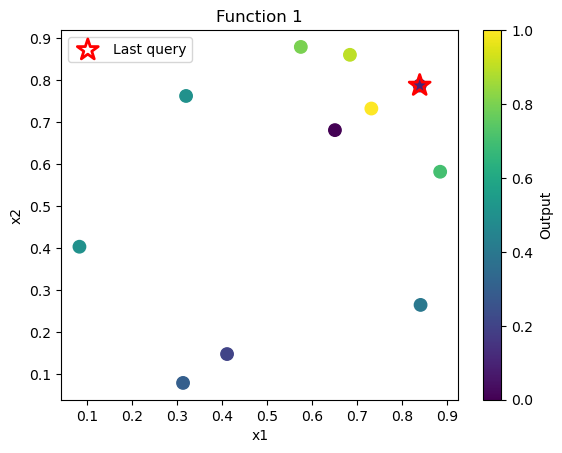

In [14]:
y_scaled = scale_scores(functions[1]["y"])

print(y_scaled)
plot_2d(1, y_scaled)

above i wanted to get a clearer visual picture of the promising region which seems to be approx (0.7, 0.8) - lets see if our new strategy agrees with this for the new query

In [15]:
validate_kernels(1)

[(('Matern', 0.05), np.float64(0.0006805348479151934)),
 (('RBF', 0.05), np.float64(0.0006846801600559985)),
 (('RQ', 0.05), np.float64(0.0007096467827269751)),
 (('Matern', 0.1), np.float64(0.0007326717601635349)),
 (('RQ', 0.1), np.float64(0.0008007521874227229)),
 (('RBF', 0.1), np.float64(0.0008387942257437522)),
 (('Matern', 0.2), np.float64(0.0010189123427982137)),
 (('RQ', 0.2), np.float64(0.0011625388955434923)),
 (('RBF', 0.2), np.float64(0.0013996939691102216)),
 (('Matern', 0.5), np.float64(0.001580467168858373)),
 (('RQ', 0.5), np.float64(0.0020516357148846346)),
 (('RBF', 0.5), np.float64(0.0036196004026023566))]

LOOCV showed that all three kernels performed best with a short length scale of 0.05, suggesting that F1 may vary substantially over small changes in input. Matérn 5/2 achieved the lowest MAE, although its performance was very close to RBF at the same length scale.

In [16]:
best_kernel = Matern(length_scale=0.05, nu=2.5)

gp_f1_scaled = fit_gp(
    1,
    best_kernel,
    transform=True
)

/var/folders/mj/nf6ln7jj63d4qc8bm0xr90r40000gn/T/ipykernel_48360/2901051345.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


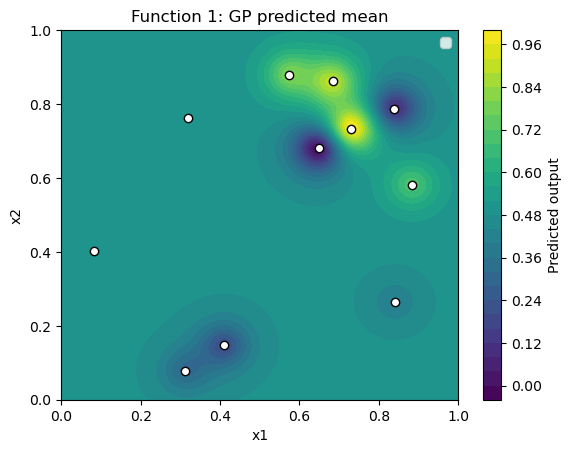

In [17]:
plot_gp_2d(1, gp_f1_scaled)

#### ucb, ei, pi

In [18]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(10000, 2)

In [19]:
suggestions = acquisitions(
    gp_f1_scaled,
    X_candidates,
    best_y=1.0
)

suggestions

{'UCB': array([0.72192397, 0.77351919]),
 'EI': array([0.72870925, 0.76121152]),
 'PI': array([0.7362376 , 0.73221756])}

all three acquisition functions suggest querying a similar region. this also aligns with my own observations, as F1 appears highly sensitive to small changes in the inputs, so exploiting the promising region around the current best point seems appropriate.

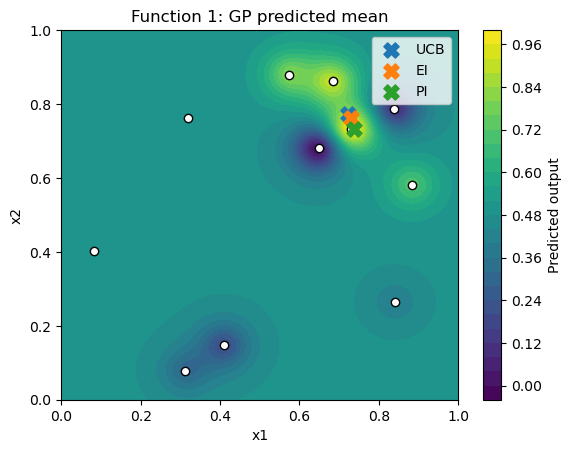

In [20]:
plot_gp_2d(1, gp_f1_scaled, suggestions)

I am selecting the EI suggestion as it exploits the promising region around the current best point while still testing a nearby unexplored location.

#### chosen query for F1

`0.728709-0.761212`

### Function 2

Function 2
Latest: X=[0.799891 0.925328], y=0.03788056227520092
Best:   X=[0.70263656 0.9265642 ], y=0.6112052157614438


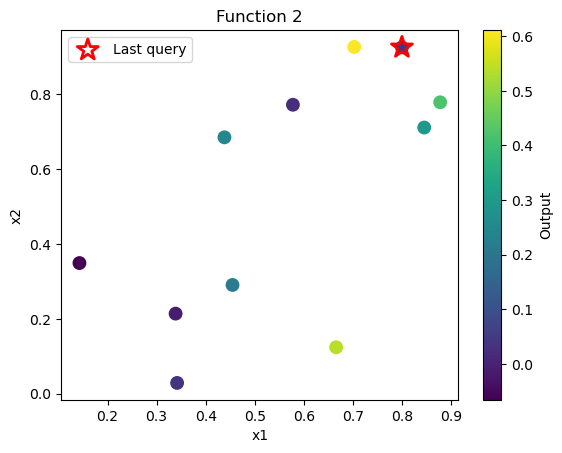

In [21]:
check_result(2)
plot_2d(2)

In [22]:
validate_kernels(2)

[(('RBF', 0.05), np.float64(0.20737600430302125)),
 (('Matern', 0.05), np.float64(0.20938607005730497)),
 (('RQ', 0.05), np.float64(0.2189016721919299)),
 (('Matern', 0.1), np.float64(0.244772802084844)),
 (('RQ', 0.1), np.float64(0.25704889550509086)),
 (('RBF', 0.1), np.float64(0.2656391445711987)),
 (('Matern', 0.2), np.float64(0.3069147146195982)),
 (('RQ', 0.2), np.float64(0.3243248422797824)),
 (('Matern', 0.5), np.float64(0.3489653157336504)),
 (('RBF', 0.2), np.float64(0.3704893285629593)),
 (('RQ', 0.5), np.float64(0.41818696198796224)),
 (('RBF', 0.5), np.float64(0.7522263030091537))]

In [23]:
best_kernel_f2 = RBF(length_scale=0.05)
gp_f2 = fit_gp(2, best_kernel_f2)

In [24]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(10000, 2)

for beta in [1, 1.96, 3, 5]:
    result = acquisitions(
        gp_f2,
        X_candidates,
        best_y=functions[2]["y"].max(),
        beta=beta
    )
    print(beta, result["UCB"])

1 [0.67532353 0.93249587]
1.96 [0.65866135 0.93155491]
3 [0.65365648 0.95622117]
5 [0.64686022 0.97029373]


In [25]:
suggestions_f2 = acquisitions(
    gp_f2,
    X_candidates,
    best_y=functions[2]["y"].max(),
    beta=3
)

suggestions_f2

{'UCB': array([0.65365648, 0.95622117]),
 'EI': array([0.67532353, 0.93249587]),
 'PI': array([0.69823299, 0.92618892])}

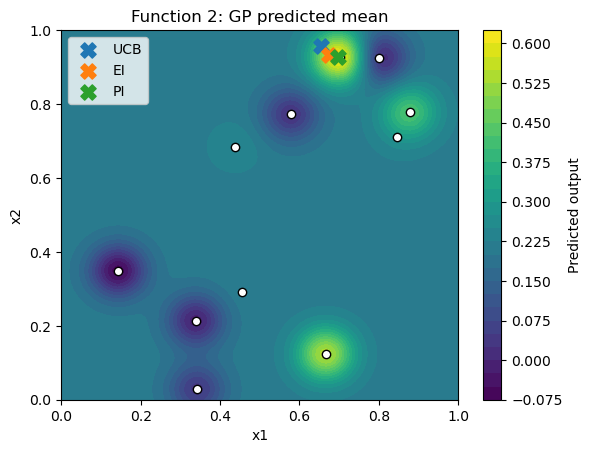

In [26]:
plot_gp_2d(2, gp_f2, suggestions_f2)

Looking back at my initial hypothesis from last week, I still believe that the region around `x1 = 0.69-0.71` is particularly promising. So, I want to take a more exploratory approach than the GP suggestions, which appear to be exploitative around the current best.

#### chosen query for F2

`0.69-0.5`

### Function 3

In [27]:
check_result(3)
validate_kernels(3)

Function 3
Latest: X=[0.491183 0.678883 0.145856], y=-0.09952109690023639
Best:   X=[0.49258141 0.61159319 0.34017639], y=-0.034835313350078584


[(('RQ', 0.05), np.float64(0.04618287212134109)),
 (('Matern', 0.05), np.float64(0.04649202771144283)),
 (('RBF', 0.05), np.float64(0.046720651942249974)),
 (('Matern', 0.1), np.float64(0.047070853984258414)),
 (('RBF', 0.1), np.float64(0.047269372351810154)),
 (('RQ', 0.1), np.float64(0.049625812326912204)),
 (('Matern', 0.2), np.float64(0.05281381535140505)),
 (('RBF', 0.2), np.float64(0.05719524070861856)),
 (('RQ', 0.2), np.float64(0.05773957578206314)),
 (('Matern', 0.5), np.float64(0.06858896909661048)),
 (('RQ', 0.5), np.float64(0.06875914022126248)),
 (('RBF', 0.5), np.float64(0.08059369623533787))]

In [28]:
best_kernel_f3 = RationalQuadratic(
    length_scale=0.05,
    alpha=1.0
)

gp_f3 = fit_gp(3, best_kernel_f3)

In [29]:
rng = np.random.RandomState(42)
X_candidates_f3 = rng.rand(20000, 3)

suggestions_f3 = acquisitions(
    gp_f3,
    X_candidates_f3,
    best_y=functions[3]["y"].max(),
    beta=1.96
)

suggestions_f3

{'UCB': array([0.231979  , 0.23963812, 0.42995773]),
 'EI': array([0.18113501, 0.27089522, 0.41896845]),
 'PI': array([0.49636625, 0.59684285, 0.33424389])}

In [30]:
def plot_3d(i, suggestions=None):
    X, y = functions[i]["X"], functions[i]["y"]

    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    p = ax.scatter(X[:, 0], X[:, 1], X[:, 2],
                   c=y, cmap="viridis", s=70)

    # Last week's query
    ax.scatter(*X[-1], marker="*", s=300,
               edgecolors="red", facecolors="none",
               linewidths=2, label="Last week's query")

    if suggestions:
        for name, point in suggestions.items():
            ax.scatter(*point, marker="X", s=150, label=name)

    ax.set_xlabel("x1")
    ax.set_ylabel("x2")
    ax.set_zlabel("x3")
    ax.set_title(f"Function {i}")
    ax.legend()
    plt.colorbar(p, label="Output")
    plt.show()

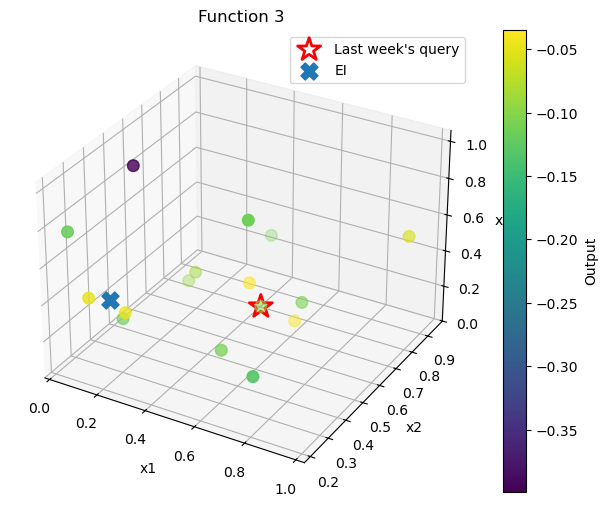

In [31]:
plot_3d(3, {
    "EI": suggestions_f3["EI"]
})

In [32]:
for name, point in suggestions_f3.items():
    mean, std = gp_f3.predict(point.reshape(1, -1), return_std=True)
    print(name, "mean:", round(mean[0], 4),
          "uncertainty:", round(std[0], 4))

UCB mean: -0.0756 uncertainty: 0.0742
EI mean: -0.0654 uncertainty: 0.0683
PI mean: -0.0385 uncertainty: 0.0256


After considering the previous query and comparing the acquisition functions, I decided to use EI for F3. Last week's query was already relatively exploratory and did not improve the current best, so I did not want to pursue an even more uncertain UCB suggestion. However, PI was very close to the existing best point and therefore offered little exploration. EI provides a compromise by exploring a different region while still being supported by relatively strong existing observations.

#### chosen query for F3

`0.181135-0.270895-0.418968`

### Function 4

In [33]:
check_result(4)
validate_kernels(4)

Function 4
Latest: X=[0.517542 0.395784 0.479356 0.197097], y=-5.1373413616802495
Best:   X=[0.57776561 0.42877174 0.42582587 0.24900741], y=-4.025542281908162


[(('RBF', 0.5), np.float64(1.5767689209705935)),
 (('RQ', 0.5), np.float64(1.6563346205904101)),
 (('Matern', 0.5), np.float64(2.1210494470107784)),
 (('RQ', 0.2), np.float64(3.0052362270128166)),
 (('RBF', 0.2), np.float64(3.48454684089236)),
 (('Matern', 0.2), np.float64(3.5089430645026085)),
 (('RQ', 0.1), np.float64(3.8680453358653413)),
 (('RBF', 0.1), np.float64(4.57837501125815)),
 (('Matern', 0.1), np.float64(4.70568274573134)),
 (('RQ', 0.05), np.float64(4.946534807823547)),
 (('Matern', 0.05), np.float64(5.684324958287289)),
 (('RBF', 0.05), np.float64(5.706604465757145))]

unlike F2/F3, the evidence suggests F4 has a considerably smoother landscape since all kernels perform considerably better with length scale 0.5

In [34]:
best_kernel_f4 = RBF(length_scale=0.5)
gp_f4 = fit_gp(4, best_kernel_f4)

In [35]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(20000, 4)

suggestions_f4 = acquisitions(
    gp_f4,
    X_candidates,
    best_y=functions[4]["y"].max(),
    beta=1.96
)

suggestions_f4

{'UCB': array([0.40447668, 0.41325432, 0.30310769, 0.43435853]),
 'EI': array([0.50797812, 0.51621189, 0.32476775, 0.42409928]),
 'PI': array([0.59603016, 0.46038618, 0.36440987, 0.35300475])}

In [36]:
check_uncertainty(gp_f4, suggestions_f4)

UCB: mean=-1.0014, uncertainty=0.9903
EI: mean=-0.9095, uncertainty=0.6655
PI: mean=-2.2841, uncertainty=0.2835


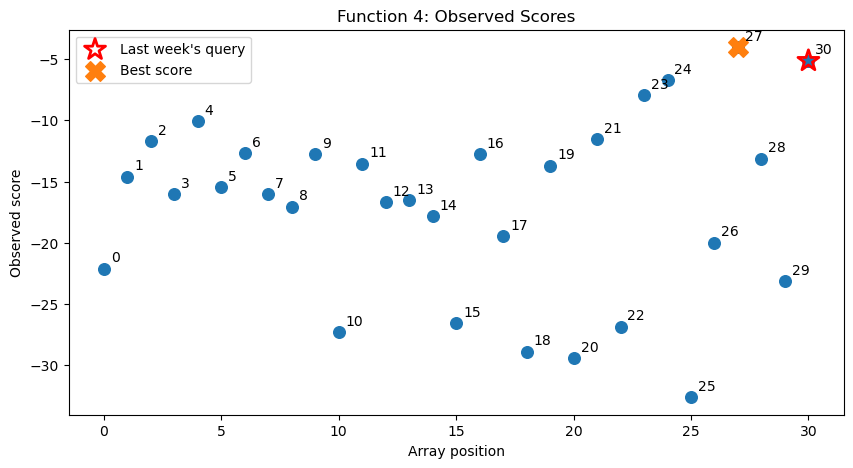

In [37]:
plot_scores(4)

based on this plot, exploiting the `0.577766-0.428772-0.425826-0.249007` region seems to be promising. now i will check to see if the GP agrees.

In [38]:
suggestions_f4 = acquisitions(
    gp_f4,
    X_candidates,
    best_y=functions[4]["y"].max(),
    beta=1.96
)

print(suggestions_f4)
check_uncertainty(gp_f4, suggestions_f4)

{'UCB': array([0.40447668, 0.41325432, 0.30310769, 0.43435853]), 'EI': array([0.50797812, 0.51621189, 0.32476775, 0.42409928]), 'PI': array([0.59603016, 0.46038618, 0.36440987, 0.35300475])}
UCB: mean=-1.0014, uncertainty=0.9903
EI: mean=-0.9095, uncertainty=0.6655
PI: mean=-2.2841, uncertainty=0.2835


For F4, I chose to take a more exploitative approach. The previous query produced the second-best observed result, providing further evidence that the region surrounding the current best is promising. PI suggested a nearby point with substantially lower uncertainty than EI and UCB, while still exploring a new combination of inputs. I therefore chose the PI suggestion to refine this promising region rather than taking a larger exploratory step.

#### chosen query for F4

`0.59603016-0.46038618-0.36440987-0.35300475`

### Function 5

In [39]:
check_result(5)
validate_kernels(5)

Function 5
Latest: X=[0.204881 0.87783  0.879582 0.870578], y=1192.2995655092311
Best:   X=[0.204881 0.87783  0.879582 0.870578], y=1192.2995655092311


[(('RQ', 0.2), np.float64(92.18831729582874)),
 (('RQ', 0.1), np.float64(103.6297644159703)),
 (('Matern', 0.2), np.float64(107.45006078002436)),
 (('Matern', 0.5), np.float64(109.75342531056434)),
 (('RBF', 0.2), np.float64(116.56969384787901)),
 (('RQ', 0.5), np.float64(118.14334394741283)),
 (('RQ', 0.05), np.float64(145.38072387426024)),
 (('Matern', 0.1), np.float64(147.2910024847889)),
 (('RBF', 0.5), np.float64(147.44670528479634)),
 (('RBF', 0.1), np.float64(149.84307527380983)),
 (('RBF', 0.05), np.float64(164.75383416651195)),
 (('Matern', 0.05), np.float64(172.22060334350383))]

F5 prefers a moderate length scale of 0.2. 

that makes sense - F5 seems to be smoother and is likely to have a main peak rather than loads of tiny local peaks.

the significant improvement in the score means i will be prioritising exploitation to see if we can make any further improvement.

In [40]:
best_kernel_f5 = RationalQuadratic(
    length_scale=0.2,
    alpha=1.0
)

gp_f5 = fit_gp(5, best_kernel_f5)

In [41]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(20000, 4)

suggestions_f5 = acquisitions(
    gp_f5,
    X_candidates,
    best_y=functions[5]["y"].max(),
    beta=1.96
)

print(suggestions_f5)
check_uncertainty(gp_f5, suggestions_f5)

{'UCB': array([0.14933546, 0.97145707, 0.89877343, 0.94958285]), 'EI': array([0.20515681, 0.94165739, 0.90583184, 0.87001523]), 'PI': array([0.20515681, 0.94165739, 0.90583184, 0.87001523])}
UCB: mean=1120.9579, uncertainty=170.1817
EI: mean=1254.0865, uncertainty=79.5631
PI: mean=1254.0865, uncertainty=79.5631


both EI and PI agree with the exact same point, so i think that this is strong justification for the new query

#### chosen query for F5

`0.20515681-0.94165739-0.90583184-0.87001523`

### Function 6

In [42]:
validate_kernels(6)

[(('RQ', 0.5), np.float64(0.2081729053845284)),
 (('Matern', 0.5), np.float64(0.2287642151257478)),
 (('RBF', 0.5), np.float64(0.23287392206719593)),
 (('RQ', 0.2), np.float64(0.27896547360975754)),
 (('Matern', 0.2), np.float64(0.3255665763902551)),
 (('RBF', 0.2), np.float64(0.3290666674705456)),
 (('RQ', 0.1), np.float64(0.33906268678004275)),
 (('RBF', 0.1), np.float64(0.36811200327685367)),
 (('Matern', 0.1), np.float64(0.3724029118066574)),
 (('RQ', 0.05), np.float64(0.37568078930649257)),
 (('Matern', 0.05), np.float64(0.3941029844168661)),
 (('RBF', 0.05), np.float64(0.3954449836952569))]

In [43]:
best_kernel_f6 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f6 = fit_gp(6, best_kernel_f6)

In [44]:
rng = np.random.RandomState(42)
X_candidates = rng.rand(20000, 5)

suggestions_f6 = acquisitions(
    gp_f6,
    X_candidates,
    best_y=functions[6]["y"].max(),
    beta=1.96
)

print(suggestions_f6)
check_uncertainty(gp_f6, suggestions_f6)

{'UCB': array([0.38626979, 0.29408036, 0.486489  , 0.72985711, 0.04747191]), 'EI': array([0.58766905, 0.31793933, 0.55383092, 0.73070688, 0.04233495]), 'PI': array([0.64745001, 0.31107318, 0.55076849, 0.70740683, 0.02262925])}
UCB: mean=-0.6409, uncertainty=0.2484
EI: mean=-0.5661, uncertainty=0.1481
PI: mean=-0.5898, uncertainty=0.1183


Most observed scores are relatively low, with the current best only `-0.714`, so I wanted to take a more exploratory approach.
LOOCV selected Rational Quadratic (length scale = `0.5`) with the lowest MAE (`0.208`).

UCB, EI and PI showed strong agreement for x2–x5, but differed more significantly on x1.

UCB had the highest uncertainty (0.248), compared with EI (0.148) and PI (0.118). Although I would usually favour a lower-risk query, it is still relatively early in the optimisation process, so the cost of exploring a more uncertain region is lower. 

I therefore chose UCB to prioritise exploration and potentially gain useful information about a less-tested region.

#### chosen query for F6

`0.386270-0.294080-0.486489-0.729857-0.047472`

### Function 7

In [45]:
check_result(7)
validate_kernels(7)

Function 7
Latest: X=[0.034286 0.50508  0.244574 0.201216 0.411612 0.773836], y=1.212598459734991
Best:   X=[0.05789554 0.49167222 0.24742222 0.21811844 0.42042833 0.73096984], y=1.3649683044991994


[(('RQ', 0.5), np.float64(0.17002038076240486)),
 (('RQ', 0.2), np.float64(0.17032953187836924)),
 (('Matern', 0.5), np.float64(0.1728980806092327)),
 (('Matern', 0.2), np.float64(0.19018754077569475)),
 (('RBF', 0.5), np.float64(0.19042860819707264)),
 (('RBF', 0.2), np.float64(0.19073540357513327)),
 (('RQ', 0.1), np.float64(0.1912643435224665)),
 (('RBF', 0.1), np.float64(0.20905712731592926)),
 (('Matern', 0.1), np.float64(0.21262129876270852)),
 (('RQ', 0.05), np.float64(0.22112008889862797)),
 (('RBF', 0.05), np.float64(0.23306230630515692)),
 (('Matern', 0.05), np.float64(0.23840762882405409))]

In [46]:
best_kernel_f7 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f7 = fit_gp(7, best_kernel_f7)

i want to exploit the region around the best point, but in a different direction to last week's query since the result was worse but still strong 

In [47]:
# generating candidates around the best point

X, y = functions[7]["X"], functions[7]["y"]
best = X[np.argmax(y)]

rng = np.random.RandomState(42)

X_candidates = best + rng.normal(
    0, 0.1, size=(20000, 6)
)

X_candidates = np.clip(X_candidates, 0, 1)

In [48]:
suggestions_f7 = acquisitions(
    gp_f7,
    X_candidates,
    best_y=y.max(),
    beta=1.96
)

print(suggestions_f7)
check_uncertainty(gp_f7, suggestions_f7)

{'UCB': array([0.04545168, 0.3367276 , 0.27311258, 0.16705001, 0.43060575,
       0.54427672]), 'EI': array([0.07165971, 0.39219493, 0.23931834, 0.23723878, 0.38514298,
       0.56691876]), 'PI': array([0.08438572, 0.47043966, 0.25708471, 0.23596628, 0.46169193,
       0.65114874])}
UCB: mean=1.5699, uncertainty=0.1171
EI: mean=1.6115, uncertainty=0.0809
PI: mean=1.5362, uncertainty=0.0255


PI moves in the opposite direction across all six dimensions compared with last week’s query while having very low uncertainty (0.026). Therefore, I chose PI as a controlled way of testing the other side of the current best point.

#### chosen query for F7

`0.08438572-0.47043966-0.25708471-0.23596628-0.46169193-0.65114874`

### Function 8

Function 8
Latest: X=[0.076274 0.101214 0.383035 0.338493 0.113685 0.882235 0.615428 0.796463], y=9.0382459830856
Best:   X=[0.05644741 0.06595555 0.02292868 0.03878647 0.40393544 0.80105533
 0.48830701 0.89308498], y=9.598482002566342


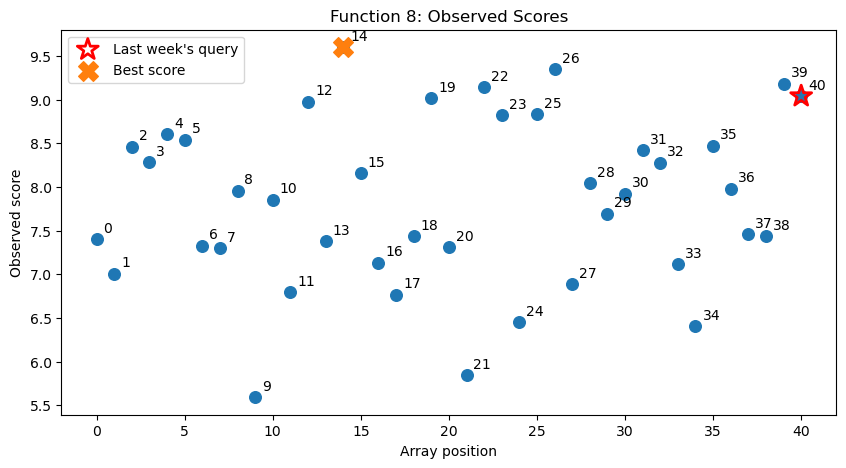

[(('RQ', 0.5), np.float64(0.379968388794042)),
 (('RBF', 0.5), np.float64(0.4289721087828828)),
 (('Matern', 0.5), np.float64(0.4603560718125219)),
 (('RQ', 0.2), np.float64(0.6187911478337259)),
 (('RQ', 0.1), np.float64(0.7392683061514466)),
 (('Matern', 0.2), np.float64(0.7579623089493595)),
 (('RBF', 0.2), np.float64(0.7649338671969014)),
 (('RQ', 0.05), np.float64(0.7922300801194456)),
 (('RBF', 0.1), np.float64(0.799867317911073)),
 (('Matern', 0.1), np.float64(0.801533856432582)),
 (('Matern', 0.05), np.float64(0.815437894125832)),
 (('RBF', 0.05), np.float64(0.81625103995591))]

In [49]:
check_result(8)
plot_scores(8)
validate_kernels(8)

In [50]:
best_kernel_f8 = RationalQuadratic(
    length_scale=0.5,
    alpha=1.0
)

gp_f8 = fit_gp(8, best_kernel_f8)

In [52]:
# local search around the best F8 point

X8, y8 = functions[8]["X"], functions[8]["y"]
best_x = X8[np.argmax(y8)]
best_y = y8.max()

rng = np.random.RandomState(42)

# candidates at several step sizes around the best point
sigmas = [0.03, 0.06, 0.10]
cands = [
    best_x + rng.normal(0, s, size=(10000, 8))
    for s in sigmas
]

# candidates that change ONE dimension at a time 
one_dim = []
for d in range(8):
    for step in [-0.15, -0.10, -0.05, 0.05, 0.10, 0.15]:
        c = best_x.copy()
        c[d] += step
        one_dim.append(c)
cands.append(np.array(one_dim))

X_local = np.vstack(cands)
X_local = np.clip(X_local, 0, 0.999999)   # stays in [0, 1) so every value starts with "0."

# running the acquisition function on the local set
suggestions_local = acquisitions(gp_f8, X_local, best_y=best_y, beta=1.96)

for name, point in suggestions_local.items():
    mean, std = gp_f8.predict(point.reshape(1, -1), return_std=True)
    diff = point - best_x
    print(f"{name}: mean={mean[0]:.3f}, std={std[0]:.3f}, "
          f"max step={np.abs(diff).max():.3f}, "
          f"dist={np.linalg.norm(diff):.3f}")
    print("   change vs best:", np.round(diff, 3))
    print("   query:", "-".join(f"{v:.6f}" for v in point))

UCB: mean=9.709, std=0.596, max step=0.343, dist=0.480
   change vs best: [ 0.001 -0.    -0.023  0.169  0.031 -0.287  0.021 -0.343]
   query: 0.056948-0.065697-0.000000-0.207297-0.434694-0.514001-0.509539-0.549974
EI: mean=9.815, std=0.539, max step=0.253, dist=0.412
   change vs best: [ 0.061  0.172 -0.023  0.253  0.081 -0.161 -0.016 -0.198]
   query: 0.116997-0.237519-0.000000-0.291682-0.485155-0.640083-0.472001-0.695456
PI: mean=9.673, std=0.113, max step=0.035, dist=0.065
   change vs best: [-0.009  0.015  0.024  0.035  0.002 -0.031 -0.011 -0.032]
   query: 0.047619-0.080988-0.047004-0.073288-0.406415-0.769833-0.477669-0.861352


For F8, last week’s global suggestion (a large step that changed x3, x4 and x5 by about 0.3 each) scored 9.04, below my best of 9.60. 

So, this week instead of sampling candidates across the whole space, I generated candidates in a trust region around my best observation (Gaussian steps of 0.03 to 0.10, plus one-dimension-at-a-time moves) and ran UCB, EI and PI on that local set. 

UCB and EI both suggested large moves (up to 0.34 in a single dimension) with high uncertainty (std about 0.54 to 0.60), and set x3 to exactly 0, which suggests extrapolation to the edge of the space. 

PI suggested a much smaller step (largest change 0.035) with far lower uncertainty (std 0.11) and a predicted mean of 9.67, slightly above my current best. 

Since F8 is 8-dimensional with only 41 observations, I chose PI as a low-risk exploitation step. If it improves on 9.60, I will take it as evidence the model is reliable locally. If not, I will shrink my steps further.

#### final query choice for F8

`0.047619-0.080988-0.047004-0.073288-0.406415-0.769833-0.477669-0.861352`